
# Содержание проекта

1. [Бизнес-постановка задачи](#1-бизнес-постановка-задачи)
2. [Подготовка данных](#2-подготовка-данных)
3. [Загрузка и первичный осмотр данных](#3-загрузка-и-первичный-осмотр-данных-предобработка-данных-data-preprocessing)
4. [Исследовательский анализ данных (EDA)](#4-исследовательский-анализ-данных-eda)
5. [Расчёт метрик (Business Metrics)](#5-расчёт-метрик-business-metrics)
6. [Прогноз показателей (Forecasting)](#6-прогноз-показателей-forecasting)
7. [Проверка гипотез (Hypothesis Testing)](#7-проверка-гипотез-hypothesis-testing)
8. [Визуализация и финальный бизнес-отчёт](#8-визуализация-и-финальный-бизнес-отчёт)
9. [Выводы и рекомендации](#9-выводы-и-рекомендации-business-insights-recommendations)





# Анализ выдачи кредитов одной команды продаж в Астане за 2023–2026 годы
<a id="section1"></a>

## 1. Бизнес-постановка задачи

### 1.1. Бизнес-проблема

Руководству команды продаж необходимо понимать, как меняются объёмы выдачи кредитов, какие продукты формируют основную долю продаж и наблюдаются ли сезонные закономерности.

Анализ исторических данных за 2023–2026 годы позволит оценить динамику кредитных выдач, выявить ключевые тенденции и определить возможности повышения эффективности продаж.

### 1.2. Цель проекта

Провести комплексный анализ выдачи кредитов одной команды продаж в Астане за 2023–2026 годы, выявить ключевые тенденции в динамике и структуре продаж, проверить исследовательские гипотезы и подготовить рекомендации для принятия управленческих решений.

### 1.3. Гипотезы исследования

**H1. Динамика выдач.** Объём кредитных выдач существенно меняется по годам.

**H2. Структура продаж.** Основная доля суммы выдач приходится на ограниченное число кредитных продуктов.

**H3. Сезонность.** Объём кредитных выдач зависит от месяца года.

Гипотезы будут проверены на основе исторических данных с использованием статистических расчётов, сравнительного анализа и визуализации.

### 1.4. Заинтересованные стороны (Stakeholders)

- **Руководитель команды продаж** — оценивает результаты работы команды и принимает управленческие решения.
- **Менеджеры по продажам** — заинтересованы в понимании динамики и структуры продаж.
- **Руководство филиала** — использует результаты анализа для оценки эффективности продаж и планирования.
- **Бизнес-аналитик / Data Analyst** — подготавливает данные, проверяет гипотезы, рассчитывает показатели и формирует рекомендации.

### 1.5. Ожидаемый результат

По итогам проекта планируется:

- Подготовить и проверить датасет для анализа.
- Рассчитать ключевые показатели кредитных выдач.
- Проанализировать динамику выдач по годам.
- Исследовать структуру продаж по кредитным продуктам.
- Выявить возможные сезонные закономерности.
- Подготовить визуализации и аналитические выводы.
- Сформулировать практические рекомендации для руководства.

### 1.6. Данные и ограничения исследования

**Источник данных:** `AstanaAnalitika_2023_2026_детализация_исправлена`.

**Период исследования:** 2023–2026 годы.

Датасет отражает кредитные выдачи одной команды продаж в Астане. Результаты исследования характеризуют данную команду и не могут автоматически распространяться на весь банк или банковский рынок Казахстана.

Поскольку данные за 2026 год охватывают неполный год, для корректного сравнения будут использоваться сопоставимые периоды разных лет.

Выводы о сезонности будут сформулированы с учётом ограничений исторических данных и количества доступных наблюдений.


## 2. Подготовка данных


На данном этапе будут подготовлены инструменты анализа, определено расположение исходного датасета и выполнена первичная загрузка данных для дальнейшего исследования.


In [1]:

# Импорт библиотек для анализа данных

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Стиль графиков
sns.set_theme(style="whitegrid")

print("Библиотеки успешно импортированы")


Библиотеки успешно импортированы


In [3]:

# Папка проекта
project_path = Path(r"C:\Users\User\project1_fintech")

# Проверяем существование папки
print("Папка проекта существует:", project_path.exists())

# Выводим список файлов
if project_path.exists():
    print("\nФайлы в папке проекта:\n")

    for file in sorted(project_path.iterdir()):
        print(file.name)
else:
    print("Проверь путь к папке проекта.")


Папка проекта существует: True

Файлы в папке проекта:

.ipynb_checkpoints
01_eda.ipynb
AstanaAnalitika_2023_2026_детализация_исправлена.xlsx



## 3. Загрузка и первичный осмотр данных. Предобработка данных (Data Preprocessing)

В рамках предобработки выполнены следующие шаги:

1. **Загрузка исходного датасета** 

2. **Первичный осмотр данных** .

3. **Обработка пропущенных значений** 

4. **Удаление ненужного столбца** 

5. **Проверка полных дубликатов** 

6. **Проверка дат** 
7. **Проверка сумм кредитных выдач** 

8. **Проверка счётчика выдач** 

9. **Проверка категориальных данных** 




In [4]:

# Путь к исходному датасету
file_path = project_path / "AstanaAnalitika_2023_2026_детализация_исправлена.xlsx"

# Загружаем данные
df = pd.read_excel(file_path)

# Первые 5 строк
display(df.head())


,Год,Месяц,Месяц_номер,Дата_выдачи,Дата_источника,Менеджер_ID,Клиент_ID,Фамилия_клиента_синтетическая,Продукт,Сумма_выдачи_KZT,Счетчик_выдачи,Продукт_из_источника
0,2023,Январь,1,2023-01-05,Из исходного отчёта,MGR_027,CL23_01_0190,Зайцев,Беззалоговый займ,5000000,1,NaN
1,2023,Январь,1,2023-01-05,Из исходного отчёта,MGR_028,CL23_01_0230,Умаров,Беззалоговый займ,4377200,1,NaN
2,2023,Январь,1,2023-01-06,Из исходного отчёта,MGR_024,CL23_01_0059,Аманов,Беззалоговый займ,5859800,1,NaN
3,2023,Январь,1,2023-01-06,Из исходного отчёта,MGR_025,CL23_01_0110,Титов,Беззалоговый займ,2601700,1,NaN
4,2023,Январь,1,2023-01-06,Из исходного отчёта,MGR_026,CL23_01_0151,Шарипов,Беззалоговый займ,1287000,1,NaN


In [5]:

# Размер датасета
print(f"Количество строк: {df.shape[0]:,}")
print(f"Количество столбцов: {df.shape[1]}")

# Названия столбцов
print("\nНазвания столбцов:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")


Количество строк: 4,049
Количество столбцов: 12

Названия столбцов:
1. Год
2. Месяц
3. Месяц_номер
4. Дата_выдачи
5. Дата_источника
6. Менеджер_ID
7. Клиент_ID
8. Фамилия_клиента_синтетическая
9. Продукт
10. Сумма_выдачи_KZT
11. Счетчик_выдачи
12. Продукт_из_источника


In [12]:

# Общая информация о датасете
df.info()

# Количество пропусков в каждом столбце
print("\nКоличество пропусков:")
display(df.isna().sum().to_frame(name="Количество пропусков"))

# Количество полных дубликатов
print("\nКоличество полных дубликатов:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4049 entries, 0 to 4048
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Год                            4049 non-null   int64         
 1   Месяц                          4049 non-null   object        
 2   Месяц_номер                    4049 non-null   int64         
 3   Дата_выдачи                    4049 non-null   datetime64[ns]
 4   Дата_источника                 4049 non-null   object        
 5   Менеджер_ID                    4049 non-null   object        
 6   Клиент_ID                      4049 non-null   object        
 7   Фамилия_клиента_синтетическая  4049 non-null   object        
 8   Продукт                        4049 non-null   object        
 9   Сумма_выдачи_KZT               4049 non-null   int64         
 10  Счетчик_выдачи                 4049 non-null   int64         
dtypes: datetime64[ns]

,Количество пропусков
Год,0
Месяц,0
Месяц_номер,0
Дата_выдачи,0
Дата_источника,0
Менеджер_ID,0
Клиент_ID,0
Фамилия_клиента_синтетическая,0
Продукт,0
Сумма_выдачи_KZT,0



Количество полных дубликатов: 0


In [7]:

# Исключаем ненужный столбец из рабочего DataFrame
df = df.drop(columns=["Продукт_из_источника"])

# Проверяем результат
print("Размер датасета после удаления столбца:", df.shape)
print("\nОставшиеся столбцы:")
print(df.columns.tolist())

print("\nКоличество пропусков:")
display(df.isna().sum().to_frame(name="Количество пропусков"))


Размер датасета после удаления столбца: (4049, 11)

Оставшиеся столбцы:
['Год', 'Месяц', 'Месяц_номер', 'Дата_выдачи', 'Дата_источника', 'Менеджер_ID', 'Клиент_ID', 'Фамилия_клиента_синтетическая', 'Продукт', 'Сумма_выдачи_KZT', 'Счетчик_выдачи']

Количество пропусков:


,Количество пропусков
Год,0
Месяц,0
Месяц_номер,0
Дата_выдачи,0
Дата_источника,0
Менеджер_ID,0
Клиент_ID,0
Фамилия_клиента_синтетическая,0
Продукт,0
Сумма_выдачи_KZT,0


In [8]:

# Проверяем минимальную и максимальную дату выдачи
print("Первая дата выдачи:", df["Дата_выдачи"].min())
print("Последняя дата выдачи:", df["Дата_выдачи"].max())

# Количество записей по годам
print("\nКоличество записей по годам:")
display(
    df.groupby("Год")
      .size()
      .reset_index(name="Количество записей")
      .sort_values("Год")
)

# Проверяем, совпадает ли год даты выдачи с полем Год
year_mismatch = (
    df["Дата_выдачи"].dt.year != df["Год"]
)

print("\nЗаписей с несовпадением года:", year_mismatch.sum())

# Проверяем, совпадает ли номер месяца с датой выдачи
month_mismatch = (
    df["Дата_выдачи"].dt.month != df["Месяц_номер"]
)

print("Записей с несовпадением месяца:", month_mismatch.sum())


Первая дата выдачи: 2023-01-05 00:00:00
Последняя дата выдачи: 2026-10-12 00:00:00

Количество записей по годам:


,Год,Количество записей
0,2023,1125
1,2024,1404
2,2025,1094
3,2026,426



Записей с несовпадением года: 0
Записей с несовпадением месяца: 0


In [9]:

# Проверяем суммы выдач
print("Минимальная сумма выдачи:", df["Сумма_выдачи_KZT"].min())
print("Максимальная сумма выдачи:", df["Сумма_выдачи_KZT"].max())

print(
    "Записей с суммой меньше или равной нулю:",
    (df["Сумма_выдачи_KZT"] <= 0).sum()
)

# Проверяем счётчик выдач
print("\nУникальные значения счётчика выдач:")
print(sorted(df["Счетчик_выдачи"].dropna().unique()))

print(
    "Записей, где счётчик выдач не равен 1:",
    (df["Счетчик_выдачи"] != 1).sum()
)


Минимальная сумма выдачи: 150000
Максимальная сумма выдачи: 100000000
Записей с суммой меньше или равной нулю: 0

Уникальные значения счётчика выдач:
[np.int64(1)]
Записей, где счётчик выдач не равен 1: 0


In [10]:

# Проверяем количество уникальных значений
print("Количество уникальных менеджеров:", df["Менеджер_ID"].nunique())
print("Количество уникальных клиентов:", df["Клиент_ID"].nunique())
print("Количество кредитных продуктов:", df["Продукт"].nunique())

# Список продуктов
print("\nКредитные продукты:")
display(
    df["Продукт"]
    .value_counts()
    .rename_axis("Продукт")
    .reset_index(name="Количество выдач")
)

# Проверяем пустые строки и пробелы в названиях продуктов
print(
    "\nПустые названия продуктов:",
    df["Продукт"].astype(str).str.strip().eq("").sum()
)

print(
    "Названия продуктов с лишними пробелами:",
    df["Продукт"].ne(df["Продукт"].astype(str).str.strip()).sum()
)

# Проверяем уникальность идентификаторов выдач, если они представлены отдельным счётчиком
print("\nРаспределение значений счётчика выдач:")
display(df["Счетчик_выдачи"].value_counts().to_frame("Количество записей"))


Количество уникальных менеджеров: 28
Количество уникальных клиентов: 3869
Количество кредитных продуктов: 2

Кредитные продукты:


,Продукт,Количество выдач
0,Залоговый займ,2676
1,Беззалоговый займ,1373



Пустые названия продуктов: 0
Названия продуктов с лишними пробелами: 0

Распределение значений счётчика выдач:


,Количество записей
Счетчик_выдачи,
1,4049



## 4. Исследовательский анализ данных (EDA)


### Основные направления анализа

1. **Анализ распределений** — изучение сумм кредитов, оценка асимметрии и выявление потенциальных выбросов с помощью гистограмм и boxplot.
2. **Корреляционный анализ** — исследование взаимосвязей между выбранными числовыми показателями с помощью корреляционной матрицы.
3. **Профилирование клиентов** — анализ количества выдач, сумм кредитования, используемых продуктов и повторной активности клиентов.
4. **Сравнительный анализ продуктов** — сравнение количества, общей суммы и среднего размера выдач по кредитным продуктам.
5. **Анализ временной динамики** — сравнение выдач по годам и месяцам, исследование возможной сезонности.
6. **Выявление бизнес-инсайтов** — формирование выводов на основе рассчитанных показателей и визуализаций.

### Инструменты анализа

- **Pandas и NumPy** — обработка данных и расчёт статистических показателей.
- **Matplotlib и Seaborn** — построение гистограмм, boxplot и корреляционных матриц.
- **Plotly** — создание интерактивных визуализаций при необходимости.

### Ожидаемый результат

Получить представление о распределении сумм кредитов, структуре продуктового портфеля, поведении клиентов и динамике выдач. Сформулировать предварительные выводы по трём бизнес-гипотезам и определить направления для их дальнейшей статистической проверки.


,Статистика
count,"4,049.00"
mean,"15,320,188.82"
std,"12,066,428.85"
min,"150,000.00"
25%,"5,955,800.00"
50%,"13,727,900.00"
75%,"21,000,000.00"
max,"100,000,000.00"


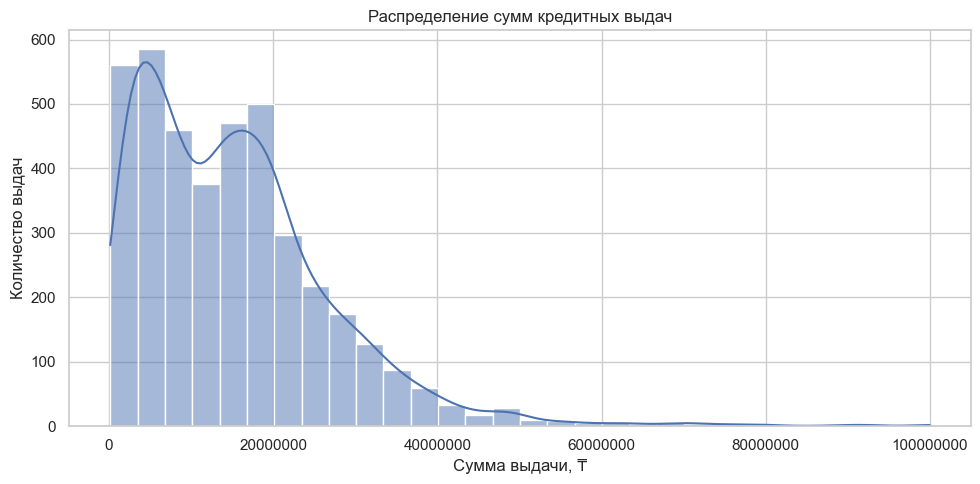

In [13]:

# Описательная статистика сумм кредитов

display(
    df["Сумма_выдачи_KZT"]
    .describe()
    .to_frame("Статистика")
)

# Гистограмма распределения сумм
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Сумма_выдачи_KZT",
    bins=30,
    kde=True
)

plt.title("Распределение сумм кредитных выдач")
plt.xlabel("Сумма выдачи, ₸")
plt.ylabel("Количество выдач")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()


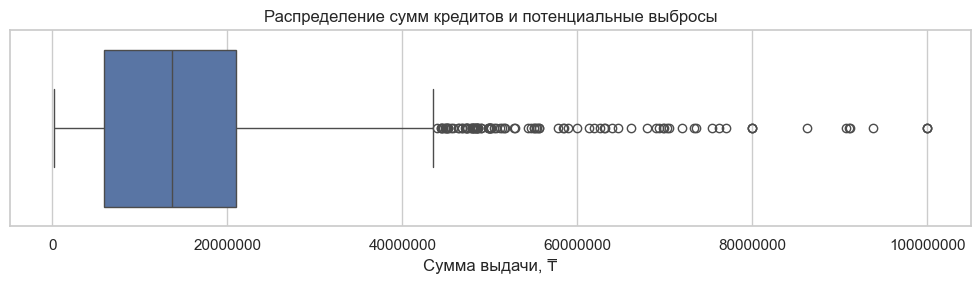

Q1: 5,955,800 ₸
Q3: 21,000,000 ₸
IQR: 15,044,200 ₸
Нижняя граница: -16,610,500 ₸
Верхняя граница: 43,566,300 ₸
Количество потенциальных выбросов: 99
Доля потенциальных выбросов: 2.45%


In [14]:

plt.figure(figsize=(10, 3))

sns.boxplot(
    data=df,
    x="Сумма_выдачи_KZT"
)

plt.title("Распределение сумм кредитов и потенциальные выбросы")
plt.xlabel("Сумма выдачи, ₸")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

# Расчёт границ выбросов методом IQR
Q1 = df["Сумма_выдачи_KZT"].quantile(0.25)
Q3 = df["Сумма_выдачи_KZT"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Сумма_выдачи_KZT"] < lower_bound) |
    (df["Сумма_выдачи_KZT"] > upper_bound)
]

print(f"Q1: {Q1:,.0f} ₸")
print(f"Q3: {Q3:,.0f} ₸")
print(f"IQR: {IQR:,.0f} ₸")
print(f"Нижняя граница: {lower_bound:,.0f} ₸")
print(f"Верхняя граница: {upper_bound:,.0f} ₸")
print(f"Количество потенциальных выбросов: {len(outliers)}")
print(f"Доля потенциальных выбросов: {len(outliers) / len(df) * 100:.2f}%")


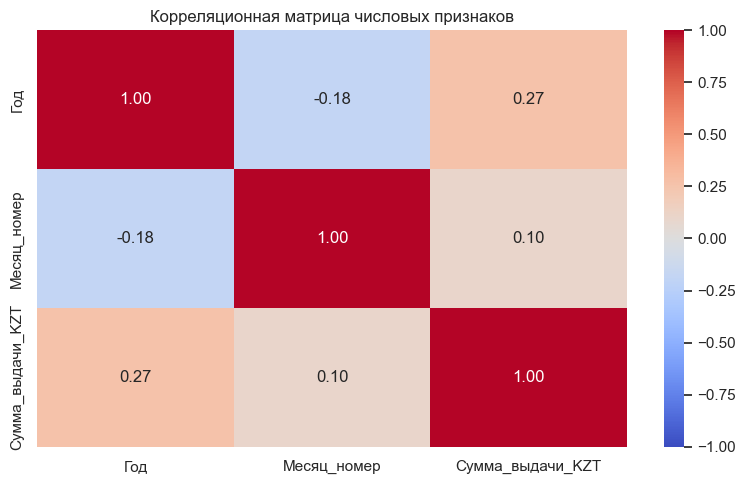

In [15]:

# Выбираем числовые признаки, имеющие смысл для анализа
correlation_columns = [
    "Год",
    "Месяц_номер",
    "Сумма_выдачи_KZT"
]

corr = df[correlation_columns].corr(method="pearson")

plt.figure(figsize=(8, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()


In [16]:

# Профиль каждого клиента
customer_profile = (
    df.groupby("Клиент_ID")
    .agg(
        Количество_выдач=("Счетчик_выдачи", "sum"),
        Общая_сумма_кредитов=("Сумма_выдачи_KZT", "sum"),
        Средний_размер_кредита=("Сумма_выдачи_KZT", "mean"),
        Количество_продуктов=("Продукт", "nunique"),
        Первая_выдача=("Дата_выдачи", "min"),
        Последняя_выдача=("Дата_выдачи", "max")
    )
    .reset_index()
)

# Категории клиентов по количеству выдач
customer_profile["Категория_клиента"] = np.where(
    customer_profile["Количество_выдач"] == 1,
    "Одна выдача",
    "Повторные выдачи"
)

display(customer_profile.head(10))

print("\nРаспределение клиентов по категориям:")
display(
    customer_profile["Категория_клиента"]
    .value_counts()
    .rename_axis("Категория")
    .reset_index(name="Количество клиентов")
)


,Клиент_ID,Количество_выдач,Общая_сумма_кредитов,Средний_размер_кредита,Количество_продуктов,Первая_выдача,Последняя_выдача,Категория_клиента
0,CL23_01_0059,1,5859800,"5,859,800.00",1,2023-01-06,2023-01-06,Одна выдача
1,CL23_01_0060,1,1062400,"1,062,400.00",1,2023-01-10,2023-01-10,Одна выдача
2,CL23_01_0061,1,5410200,"5,410,200.00",1,2023-01-11,2023-01-11,Одна выдача
3,CL23_01_0062,1,2000000,"2,000,000.00",1,2023-01-11,2023-01-11,Одна выдача
4,CL23_01_0065,1,23840000,"23,840,000.00",1,2023-01-12,2023-01-12,Одна выдача
5,CL23_01_0066,1,2246000,"2,246,000.00",1,2023-01-13,2023-01-13,Одна выдача
6,CL23_01_0067,1,2000000,"2,000,000.00",1,2023-01-13,2023-01-13,Одна выдача
7,CL23_01_0068,1,750000,"750,000.00",1,2023-01-13,2023-01-13,Одна выдача
8,CL23_01_0070,1,1000100,"1,000,100.00",1,2023-01-13,2023-01-13,Одна выдача
9,CL23_01_0072,1,4500000,"4,500,000.00",1,2023-01-20,2023-01-20,Одна выдача



Распределение клиентов по категориям:


,Категория,Количество клиентов
0,Одна выдача,3722
1,Повторные выдачи,147



### Выявленные инсайты

По результатам первичного исследовательского анализа получены следующие наблюдения:

1. **Распределение сумм кредитов.** Средняя сумма выдачи составляет 15,32 млн ₸, медианная — 13,73 млн ₸. Среднее значение выше медианы, что согласуется с правосторонней асимметрией распределения и влиянием крупных кредитов.

2. **Потенциальные выбросы.** Метод IQR выявил 99 наблюдений (2,45% датасета) с суммой выдачи выше верхней границы 43,57 млн ₸. Эти значения требуют дополнительной проверки, но не считаются ошибочными автоматически.

3. **Корреляции.** Корреляция между годом и суммой отдельной выдачи составляет 0,27, а между номером месяца и суммой выдачи — 0,10. Наблюдаемые линейные связи слабые или умеренно слабые и сами по себе не подтверждают наличие сезонности или устойчивого роста кредитования.

4. **Повторные выдачи.** У 3 722 клиентов зарегистрирована одна выдача, у 147 клиентов — повторные выдачи в пределах исследуемого датасета. Это позволяет отдельно изучить особенности повторного кредитования.

Полученные результаты являются предварительными. Для завершения EDA необходимо исследовать структуру выдач по продуктам и временную динамику, а затем сформулировать итоговые выводы по бизнес-гипотезам.


In [17]:

# Сравнение кредитных продуктов

product_analysis = (
    df.groupby("Продукт")
    .agg(
        Количество_выдач=("Счетчик_выдачи", "sum"),
        Общая_сумма_KZT=("Сумма_выдачи_KZT", "sum"),
        Средний_кредит_KZT=("Сумма_выдачи_KZT", "mean"),
        Медианный_кредит_KZT=("Сумма_выдачи_KZT", "median"),
        Уникальные_клиенты=("Клиент_ID", "nunique")
    )
    .reset_index()
)

product_analysis["Доля_выдач_%"] = (
    product_analysis["Количество_выдач"]
    / product_analysis["Количество_выдач"].sum() * 100
)

product_analysis["Доля_суммы_%"] = (
    product_analysis["Общая_сумма_KZT"]
    / product_analysis["Общая_сумма_KZT"].sum() * 100
)

display(product_analysis.round(2))


,Продукт,Количество_выдач,Общая_сумма_KZT,Средний_кредит_KZT,Медианный_кредит_KZT,Уникальные_клиенты,Доля_выдач_%,Доля_суммы_%
0,Беззалоговый займ,1373,5985776038,"4,359,632.95","4,000,000.00",1356,33.91,9.65
1,Залоговый займ,2676,56045668509,"20,943,822.31","18,525,253.00",2575,66.09,90.35


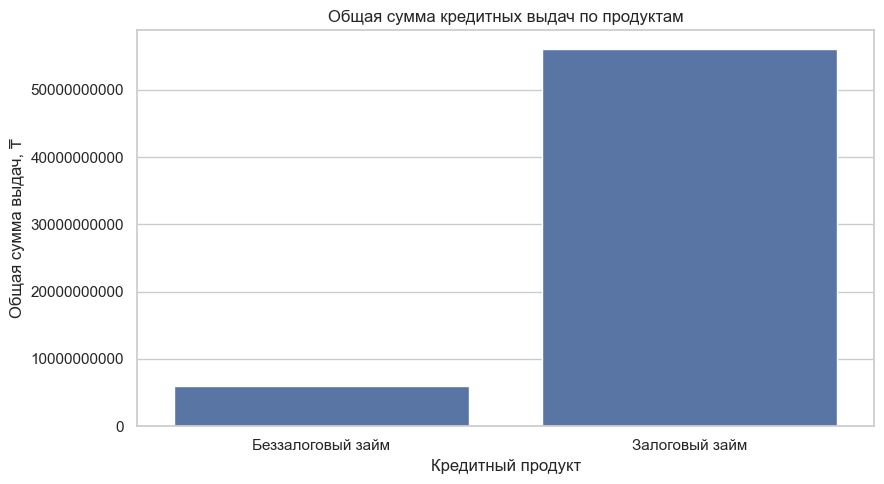

In [18]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=product_analysis,
    x="Продукт",
    y="Общая_сумма_KZT"
)

plt.title("Общая сумма кредитных выдач по продуктам")
plt.xlabel("Кредитный продукт")
plt.ylabel("Общая сумма выдач, ₸")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()



### Инсайты по структуре кредитных продуктов

1. **Доминирование залогового продукта.** Залоговые займы составляют 66,09% количества выдач и формируют 90,35% общей суммы кредитования.

2. **Различие в среднем размере кредита.** Средний размер залогового займа составляет 20,94 млн ₸, беззалогового — 4,36 млн ₸. Средняя сумма залогового займа примерно в 4,8 раза выше.

3. **Различие в структуре продаж.** Беззалоговые займы формируют 33,91% количества выдач, но только 9,65% общей суммы. Это указывает на различие продуктов по среднему размеру кредита и их вкладу в денежный объём продаж.

**Бизнес-вывод:** при оценке результатов команды необходимо анализировать одновременно количество выдач и их денежный объём, поскольку эти показатели отражают разные стороны продаж.


In [19]:

# Динамика кредитных выдач по годам и месяцам

monthly_analysis = (
    df.groupby(["Год", "Месяц_номер"])
    .agg(
        Количество_выдач=("Счетчик_выдачи", "sum"),
        Сумма_выдач_KZT=("Сумма_выдачи_KZT", "sum")
    )
    .reset_index()
    .sort_values(["Год", "Месяц_номер"])
)

display(monthly_analysis.head(15))


,Год,Месяц_номер,Количество_выдач,Сумма_выдач_KZT
0,2023,1,59,244435400
1,2023,2,48,295131040
2,2023,3,71,467368389
3,2023,4,65,822616400
4,2023,5,71,491238436
5,2023,6,96,769913693
6,2023,7,114,998510158
7,2023,8,124,1369089306
8,2023,9,110,1303611563
9,2023,10,118,1618728905


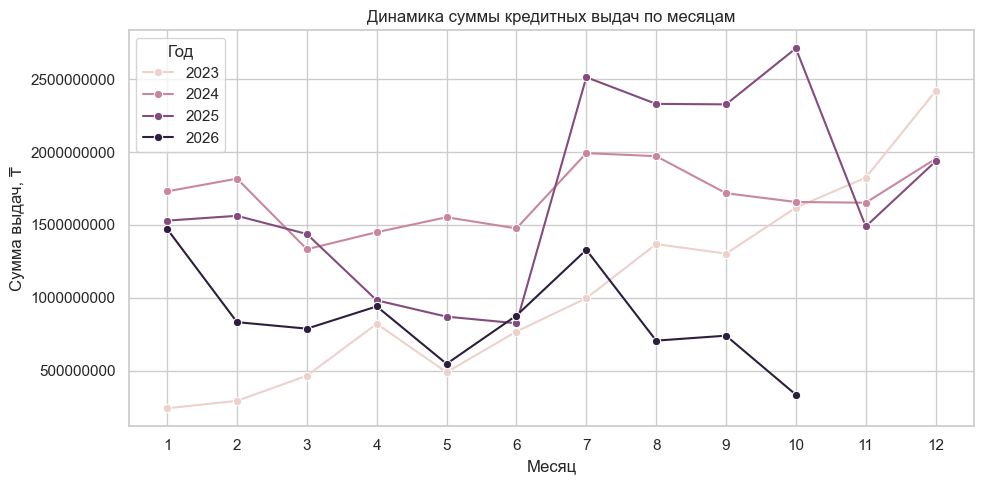

In [20]:

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_analysis,
    x="Месяц_номер",
    y="Сумма_выдач_KZT",
    hue="Год",
    marker="o"
)

plt.title("Динамика суммы кредитных выдач по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Сумма выдач, ₸")
plt.xticks(range(1, 13))
plt.ticklabel_format(axis="y", style="plain")
plt.legend(title="Год")
plt.tight_layout()
plt.show()


In [21]:

# Сравнение одинаковых периодов: январь–сентябрь

comparable_period = df[df["Месяц_номер"].between(1, 9)]

year_comparison = (
    comparable_period.groupby("Год")
    .agg(
        Количество_выдач=("Счетчик_выдачи", "sum"),
        Сумма_выдач_KZT=("Сумма_выдачи_KZT", "sum")
    )
    .reset_index()
    .sort_values("Год")
)

# Темп изменения относительно предыдущего года
year_comparison["Изменение_суммы_%"] = (
    year_comparison["Сумма_выдач_KZT"].pct_change() * 100
)

year_comparison["Изменение_количества_%"] = (
    year_comparison["Количество_выдач"].pct_change() * 100
)

display(year_comparison.round(2))


,Год,Количество_выдач,Сумма_выдач_KZT,Изменение_суммы_%,Изменение_количества_%
0,2023,758,6761914385,NaN,NaN
1,2024,1042,15043895759,122.48,37.47
2,2025,811,14382061804,-4.40,-22.17
3,2026,414,8246378937,-42.66,-48.95


In [22]:

# Проверка сезонности на полных годах: 2023–2025

seasonality_data = df[df["Год"].isin([2023, 2024, 2025])]

seasonality_analysis = (
    seasonality_data
    .groupby("Месяц_номер")
    .agg(
        Среднее_количество_выдач=("Счетчик_выдачи", "mean"),
        Средняя_сумма_выдач_KZT=("Сумма_выдачи_KZT", "mean"),
        Всего_выдач=("Счетчик_выдачи", "sum"),
        Всего_сумма_выдач_KZT=("Сумма_выдачи_KZT", "sum"),
        Количество_лет=("Год", "nunique")
    )
    .reset_index()
    .sort_values("Месяц_номер")
)

display(seasonality_analysis.round(2))


,Месяц_номер,Среднее_количество_выдач,Средняя_сумма_выдач_KZT,Всего_выдач,Всего_сумма_выдач_KZT,Количество_лет
0,1,1.00,"12,790,873.08",274,3504699224,3
1,2,1.00,"14,820,870.66",248,3675575923,3
2,3,1.00,"13,331,069.38",243,3239449860,3
3,4,1.00,"11,843,785.66",275,3257041057,3
4,5,1.00,"12,624,411.59",231,2916239077,3
5,6,1.00,"12,343,828.31",249,3073613249,3
6,7,1.00,"14,444,125.18",381,5503211695,3
7,8,1.00,"15,283,728.80",371,5670263384,3
8,9,1.00,"15,775,157.76",339,5347778479,3
9,10,1.00,"16,312,084.31",367,5986534943,3



### Общие инсайты по результатам EDA

По результатам исследовательского анализа данных о кредитных выдачах одной команды в Астане за 2023–2026 годы выявлены следующие закономерности:

1. **Структура кредитного портфеля.** Залоговые займы формируют 90,35% общей суммы выдач при доле 66,09% по количеству кредитов. Средний размер залогового займа составляет 20,94 млн ₸, что примерно в 4,8 раза выше среднего размера беззалогового займа.

2. **Распределение сумм.** Средняя сумма выдачи составляет 15,32 млн ₸, медианная — 13,73 млн ₸. Распределение имеет правостороннюю асимметрию: крупные кредиты повышают среднее значение.

3. **Потенциальные выбросы.** Метод IQR выявил 99 наблюдений (2,45% датасета) с суммой выше 43,57 млн ₸. Эти записи требуют дополнительной проверки, но не считаются ошибочными автоматически.

4. **Повторные выдачи клиентам.** Из 3 869 уникальных клиентов у 147 зарегистрировано более одной выдачи за исследуемый период. Это позволяет отдельно изучить повторное кредитование.

5. **Динамика выдач.** При сравнении января–сентября сумма выдач выросла на 122,48% в 2024 году, снизилась на 4,40% в 2025 году и на 42,66% в 2026 году относительно предыдущего года. В 2026 году снижение суммы сопровождалось сокращением количества выдач на 48,95%.

6. **Возможная сезонность.** В данных за 2023–2025 годы наибольшая совокупная сумма выдач наблюдается в декабре, а наибольшее количество выдач — в июле. Эти различия требуют статистической проверки, прежде чем делать вывод о сезонности.

7. **Корреляционный анализ.** Корреляция между годом и суммой отдельной выдачи составляет 0,27, а между номером месяца и суммой выдачи — 0,10. Эти связи не доказывают причинность и не заменяют анализ динамики совокупных выдач.

### Итоговый вывод

EDA показал, что денежный объём кредитования в значительной степени формируется залоговыми займами. Также обнаружены различия в динамике выдач по годам и месяцам, потенциальные крупные значения и небольшая доля клиентов с повторными выдачами.

На следующем этапе необходимо рассчитать доступные клиентские метрики, проверить бизнес-гипотезы статистическими методами и построить модель прогнозирования. Причины снижения выдач в 2026 году и наличие устойчивой сезонности пока не установлены.



## 5. Расчёт метрик (Business Metrics)

Цель этапа — оценить клиентскую базу и объём кредитования на одного клиента за период исследования.

Рассчитываются следующие показатели:

1. **Количество уникальных клиентов** — число клиентов, представленных в датасете.
2. **Доля клиентов с повторными выдачами (Repeat Rate)** — доля клиентов, у которых за период исследования зарегистрировано более одной выдачи.
3. **Средняя сумма выдач на клиента** — отношение общей суммы кредитных выдач к количеству уникальных клиентов.

Показатели CAC, ROI и полноценный LTV не рассчитываются из-за отсутствия данных о расходах на привлечение клиентов, доходах и прибыли банка. Конверсию заявок также нельзя определить, поскольку датасет содержит сведения о состоявшихся выдачах, но не о заявках и отказах.



In [36]:

# 5.1. Основные клиентские и бизнес-метрики

total_issuances = df["Счетчик_выдачи"].sum()
total_amount = df["Сумма_выдачи_KZT"].sum()
total_customers = df["Клиент_ID"].nunique()

# Количество выдач на каждого клиента
issuances_per_customer = (
    df.groupby("Клиент_ID")["Счетчик_выдачи"].sum()
)

repeat_customers = (issuances_per_customer > 1).sum()
single_issuance_customers = (issuances_per_customer == 1).sum()

repeat_rate = repeat_customers / total_customers * 100
average_amount_per_customer = total_amount / total_customers

# Итоговая таблица
metrics = pd.DataFrame({
    "Метрика": [
        "Количество выдач",
        "Общая сумма выдач, ₸",
        "Уникальные клиенты",
        "Клиенты с одной выдачей",
        "Клиенты с повторными выдачами",
        "Доля клиентов с повторными выдачами, %",
        "Средняя сумма выдач на клиента, ₸"
    ],
    "Значение": [
        total_issuances,
        total_amount,
        total_customers,
        single_issuance_customers,
        repeat_customers,
        repeat_rate,
        average_amount_per_customer
    ]
})

display(metrics.round(2))


,Метрика,Значение
0,Количество выдач,"4,049.00"
1,"Общая сумма выдач, ₸","62,031,444,547.00"
2,Уникальные клиенты,"3,869.00"
3,Клиенты с одной выдачей,"3,722.00"
4,Клиенты с повторными выдачами,147.00
5,"Доля клиентов с повторными выдачами, %",3.80
6,"Средняя сумма выдач на клиента, ₸","16,032,939.92"



### Выводы по бизнес-метрикам

За исследуемый период зарегистрировано 4 049 кредитных выдач на общую сумму 62,03 млрд ₸. Количество уникальных клиентов составило 3 869.

У 147 клиентов зафиксированы повторные выдачи, что соответствует Repeat Rate 3,80%. Средняя сумма кредитных выдач в расчёте на одного уникального клиента составила 16,03 млн ₸.

Полученные показатели характеризуют объём кредитования и повторную активность клиентов в пределах исследуемого периода. Они не отражают прибыльность клиентов или доходность кредитных продуктов.



## 6. Прогноз показателей (Forecasting)

### Цель исследования

Построить модель линейной регрессии для прогнозирования месячной суммы кредитных выдач в Астане на основе исторических данных за 2023–2026 годы.

В качестве целевой переменной используется общая сумма кредитных выдач за месяц. В качестве факторов используются временной тренд и календарный месяц.

Для оценки качества модели применяются метрики R² и MAE. Проверка качества выполняется на хронологически отложенной тестовой выборке.

Данные за октябрь 2026 года исключаются из обучения, поскольку месяц представлен не полностью.


In [37]:

# 6 Подготовка временного ряда

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Исключаем неполный октябрь 2026 года
forecast_df = df[
    df["Дата_выдачи"] < "2026-10-01"
].copy()

# Агрегируем выдачи по месяцам
monthly_forecast = (
    forecast_df
    .groupby(pd.Grouper(key="Дата_выдачи", freq="MS"))
    .agg(
        Сумма_выдач_KZT=("Сумма_выдачи_KZT", "sum"),
        Количество_выдач=("Счетчик_выдачи", "sum")
    )
    .reset_index()
    .sort_values("Дата_выдачи")
)

# Создаём временные признаки
monthly_forecast["Время"] = np.arange(len(monthly_forecast))
monthly_forecast["Месяц"] = monthly_forecast["Дата_выдачи"].dt.month

print("Количество месяцев:", len(monthly_forecast))
print("Первый месяц:", monthly_forecast["Дата_выдачи"].min().strftime("%Y-%m"))
print("Последний месяц:", monthly_forecast["Дата_выдачи"].max().strftime("%Y-%m"))

display(monthly_forecast.tail(10))


Количество месяцев: 45
Первый месяц: 2023-01
Последний месяц: 2026-09


,Дата_выдачи,Сумма_выдач_KZT,Количество_выдач,Время,Месяц
35,2025-12-01,1935907500,104,35,12
36,2026-01-01,1472476519,81,36,1
37,2026-02-01,834328291,44,37,2
38,2026-03-01,789772231,41,38,3
39,2026-04-01,942194887,49,39,4
40,2026-05-01,548650800,27,40,5
41,2026-06-01,879632851,50,41,6
42,2026-07-01,1329857006,54,42,7
43,2026-08-01,707805177,34,43,8
44,2026-09-01,741661175,34,44,9


In [38]:

#  Обучение и тестирование модели

# Кодируем календарный месяц как категориальный признак
X = pd.get_dummies(
    monthly_forecast[["Время", "Месяц"]].assign(
        Месяц=lambda x: x["Месяц"].astype(str)
    ),
    columns=["Месяц"],
    drop_first=True,
    dtype=int
)

y = monthly_forecast["Сумма_выдач_KZT"]

# Хронологическое разделение 80/20
split_index = int(len(monthly_forecast) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Обучение
model = LinearRegression()
model.fit(X_train, y_train)

# Прогноз для тестового периода
y_pred = model.predict(X_test)

# Метрики качества
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Количество месяцев для обучения: {len(X_train)}")
print(f"Количество месяцев для тестирования: {len(X_test)}")
print(f"R²: {r2:.3f}")
print(f"MAE: {mae:,.0f} ₸")


Количество месяцев для обучения: 36
Количество месяцев для тестирования: 9
R²: -16.088
MAE: 1,082,029,372 ₸


,Дата,Фактическая_сумма_KZT,Прогноз_KZT
0,2026-01-01,1472476519,"1,826,235,220.00"
1,2026-02-01,834328291,"1,883,194,119.00"
2,2026-03-01,789772231,"1,737,818,765.00"
3,2026-04-01,942194887,"1,743,682,497.00"
4,2026-05-01,548650800,"1,630,081,837.00"
5,2026-06-01,879632851,"1,682,539,895.00"
6,2026-07-01,1329857006,"2,492,406,043.00"
7,2026-08-01,707805177,"2,548,089,940.00"
8,2026-09-01,741661175,"2,440,594,971.00"


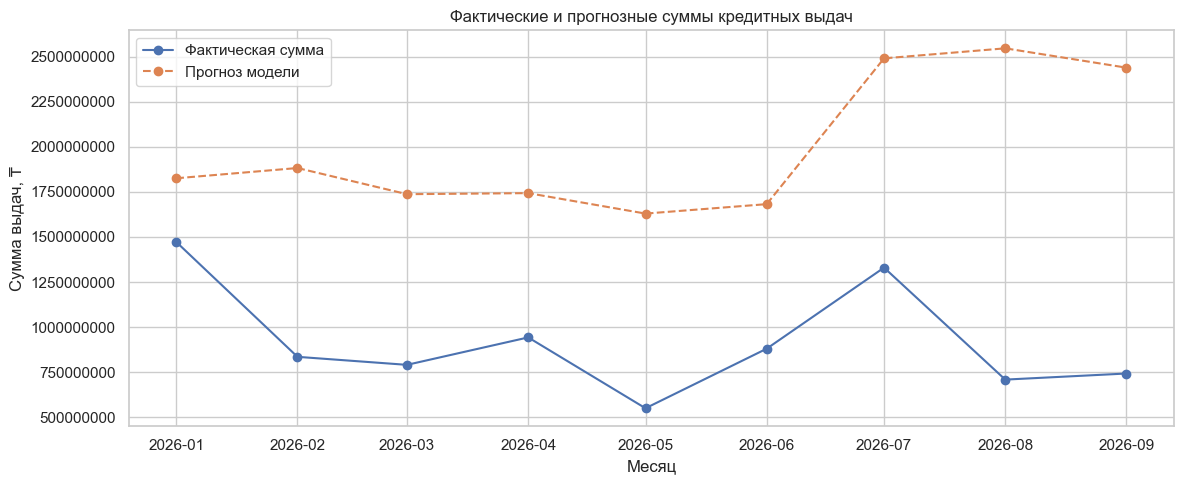

In [39]:

# Таблица фактических и прогнозных сумм
test_results = pd.DataFrame({
    "Дата": monthly_forecast["Дата_выдачи"].iloc[split_index:].values,
    "Фактическая_сумма_KZT": y_test.values,
    "Прогноз_KZT": y_pred
})

display(test_results.round(0))

# График
plt.figure(figsize=(12, 5))

plt.plot(
    test_results["Дата"],
    test_results["Фактическая_сумма_KZT"],
    marker="o",
    label="Фактическая сумма"
)

plt.plot(
    test_results["Дата"],
    test_results["Прогноз_KZT"],
    marker="o",
    linestyle="--",
    label="Прогноз модели"
)

plt.title("Фактические и прогнозные суммы кредитных выдач")
plt.xlabel("Месяц")
plt.ylabel("Сумма выдач, ₸")
plt.ticklabel_format(axis="y", style="plain")
plt.legend()
plt.tight_layout()
plt.show()


In [40]:

# Коэффициенты влияния факторов
coefficients = pd.DataFrame({
    "Фактор": X_train.columns,
    "Коэффициент": model.coef_
}).sort_values(
    "Коэффициент",
    key=abs,
    ascending=False
)

display(coefficients.round(2))

print(f"Свободный член модели: {model.intercept_:,.0f} ₸")


,Фактор,Коэффициент
3,Месяц_12,"632,372,591.58"
1,Месяц_10,"580,527,768.66"
10,Месяц_8,"529,937,427.73"
9,Месяц_7,"501,670,287.44"
11,Месяц_9,"395,025,703.36"
7,Месяц_5,"-305,820,406.49"
8,Месяц_6,"-280,779,105.19"
2,Месяц_11,"213,145,721.95"
6,Месяц_4,"-164,802,990.45"
5,Месяц_3,"-143,249,966.74"


Свободный член модели: 839,232,002 ₸



### Выводы по модели линейной регрессии

Для прогнозирования месячной суммы кредитных выдач построена модель линейной регрессии с временным трендом и календарными признаками.

Модель обучена на 36 месяцах исторических данных и протестирована на следующих 9 месяцах.

Результаты оценки:
- R² = -16,088.
- MAE = 1,08 млрд ₸.

На тестовом периоде модель систематически завышает фактические суммы выдач. Это указывает на низкое качество прогноза и ограниченную способность модели отражать изменения динамики кредитования.

**Вывод:** текущая модель не подходит для надёжного бизнес-прогнозирования. Полученные результаты следует рассматривать как экспериментальный результат, показывающий ограничения линейной регрессии на имеющихся данных.



## 7. Проверка гипотез (Hypothesis Testing)

Цель этапа — проверить, подтверждаются ли выявленные в ходе EDA закономерности с помощью статистических тестов.

Проверяются три гипотезы:

**H1. Динамика выдач**
- H₀: распределения месячных сумм выдач не имеют статистически значимых различий между годами.
- H₁: хотя бы один год отличается от остальных.

**H2. Различия между продуктами**
- H₀: распределения сумм отдельных выдач по залоговым и беззалоговым займам не различаются.
- H₁: распределения сумм выдач по двум продуктам различаются.

**H3. Сезонность**
- H₀: распределения месячных сумм выдач не различаются между календарными месяцами.
- H₁: хотя бы один календарный месяц отличается от остальных.

Для проверки используются непараметрические статистические тесты, поскольку суммы выдач имеют асимметричное распределение и потенциальные выбросы.

Уровень статистической значимости: α = 0,05.


In [41]:

from scipy.stats import kruskal, mannwhitneyu
import pandas as pd
import numpy as np

alpha = 0.05
results = []

# H1. Сравнение месячных сумм выдач по годам
# Используем одинаковый период: январь–сентябрь
h1_data = df[df["Месяц_номер"].between(1, 9)].copy()

monthly_by_year = (
    h1_data.groupby(["Год", "Месяц_номер"])
    ["Сумма_выдачи_KZT"]
    .sum()
    .reset_index()
)

groups_h1 = [
    monthly_by_year.loc[
        monthly_by_year["Год"] == year,
        "Сумма_выдачи_KZT"
    ].values
    for year in sorted(monthly_by_year["Год"].unique())
]

stat_h1, p_h1 = kruskal(*groups_h1)

results.append({
    "Гипотеза": "H1: различия между годами",
    "Тест": "Краскела — Уоллиса",
    "Статистика": stat_h1,
    "p-value": p_h1,
    "Результат": (
        "Есть статистически значимые различия"
        if p_h1 < alpha
        else "Статистически значимые различия не выявлены"
    )
})

# H2. Сравнение сумм выдач по двум продуктам
secured = df.loc[
    df["Продукт"] == "Залоговый займ",
    "Сумма_выдачи_KZT"
]

unsecured = df.loc[
    df["Продукт"] == "Беззалоговый займ",
    "Сумма_выдачи_KZT"
]

stat_h2, p_h2 = mannwhitneyu(
    secured,
    unsecured,
    alternative="two-sided"
)

results.append({
    "Гипотеза": "H2: различия между продуктами",
    "Тест": "Манна — Уитни",
    "Статистика": stat_h2,
    "p-value": p_h2,
    "Результат": (
        "Есть статистически значимые различия"
        if p_h2 < alpha
        else "Статистически значимые различия не выявлены"
    )
})

# H3. Сравнение месячных сумм по календарным месяцам
# Используем полные годы 2023–2025
h3_data = df[df["Год"].isin([2023, 2024, 2025])].copy()

monthly_by_season = (
    h3_data.groupby(["Год", "Месяц_номер"])
    ["Сумма_выдачи_KZT"]
    .sum()
    .reset_index()
)

groups_h3 = [
    monthly_by_season.loc[
        monthly_by_season["Месяц_номер"] == month,
        "Сумма_выдачи_KZT"
    ].values
    for month in range(1, 13)
]

stat_h3, p_h3 = kruskal(*groups_h3)

results.append({
    "Гипотеза": "H3: сезонные различия",
    "Тест": "Краскела — Уоллиса",
    "Статистика": stat_h3,
    "p-value": p_h3,
    "Результат": (
        "Есть статистически значимые различия"
        if p_h3 < alpha
        else "Статистически значимые различия не выявлены"
    )
})

# Итоговая таблица
hypothesis_results = pd.DataFrame(results)

display(hypothesis_results.round(4))


,Гипотеза,Тест,Статистика,p-value,Результат
0,H1: различия между годами,Краскела — Уоллиса,19.85,0.00,Есть статистически значимые различия
1,H2: различия между продуктами,Манна — Уитни,"3,631,177.00",0.00,Есть статистически значимые различия
2,H3: сезонные различия,Краскела — Уоллиса,17.54,0.09,Статистически значимые различия не выявлены


In [42]:

# Точные p-value для отчёта

for name, statistic, p_value in [
    ("H1: различия между годами", stat_h1, p_h1),
    ("H2: различия между продуктами", stat_h2, p_h2),
    ("H3: сезонные различия", stat_h3, p_h3)
]:
    print(
        f"{name}: статистика = {statistic:.4f}, "
        f"p-value = {p_value:.8f}"
    )


H1: различия между годами: статистика = 19.8488, p-value = 0.00018244
H2: различия между продуктами: статистика = 3631177.0000, p-value = 0.00000000
H3: сезонные различия: статистика = 17.5405, p-value = 0.09287237



### Выводы по проверке гипотез

Для проверки гипотез использован уровень статистической значимости α = 0,05.

**H1. Различия между годами**

Тест Краскела — Уоллиса выявил статистически значимые различия между годовыми группами месячных сумм выдач (H = 19,8488; p = 0,00018244). Нулевая гипотеза отвергается. Результат подтверждает наличие различий между годами, но не устанавливает их причины и не показывает, между какими конкретно годами различия наиболее выражены.

**H2. Различия между продуктами**

Тест Манна — Уитни выявил статистически значимые различия в распределениях сумм отдельных выдач по залоговым и беззалоговым займам (U = 3 631 177; p < 0,00000001). Нулевая гипотеза отвергается. Результат согласуется с описательным анализом, согласно которому средний размер залогового займа существенно выше.

**H3. Сезонные различия**

Тест Краскела — Уоллиса не выявил статистически значимых различий между календарными месяцами (H = 17,5405; p = 0,09287237). При уровне значимости 0,05 нет достаточных оснований отвергнуть нулевую гипотезу. Наличие устойчивой сезонности не подтверждено.

### Общий вывод

Статистическая проверка выявила различия в месячных суммах выдач между годовыми группами и в суммах кредитов по продуктам. При этом статистических доказательств различий между календарными месяцами на выбранном уровне значимости не получено.

Результаты показывают наличие статистических различий, но сами по себе не доказывают причинно-следственные связи. Для H1 и H3 также необходимо учитывать временную структуру наблюдений и возможную зависимость показателей соседних месяцев.



## 8. Визуализация и финальный бизнес-отчёт

Цель этапа — представить результаты анализа кредитных выдач в наглядном и понятном для бизнеса формате.

Дашборд включает:
- ключевые показатели кредитования (KPI);
- динамику суммы и количества выдач по месяцам;
- сравнение залоговых и беззалоговых займов;
- результаты статистической проверки бизнес-гипотез.

Инструменты: Python, Pandas, Matplotlib и Seaborn.


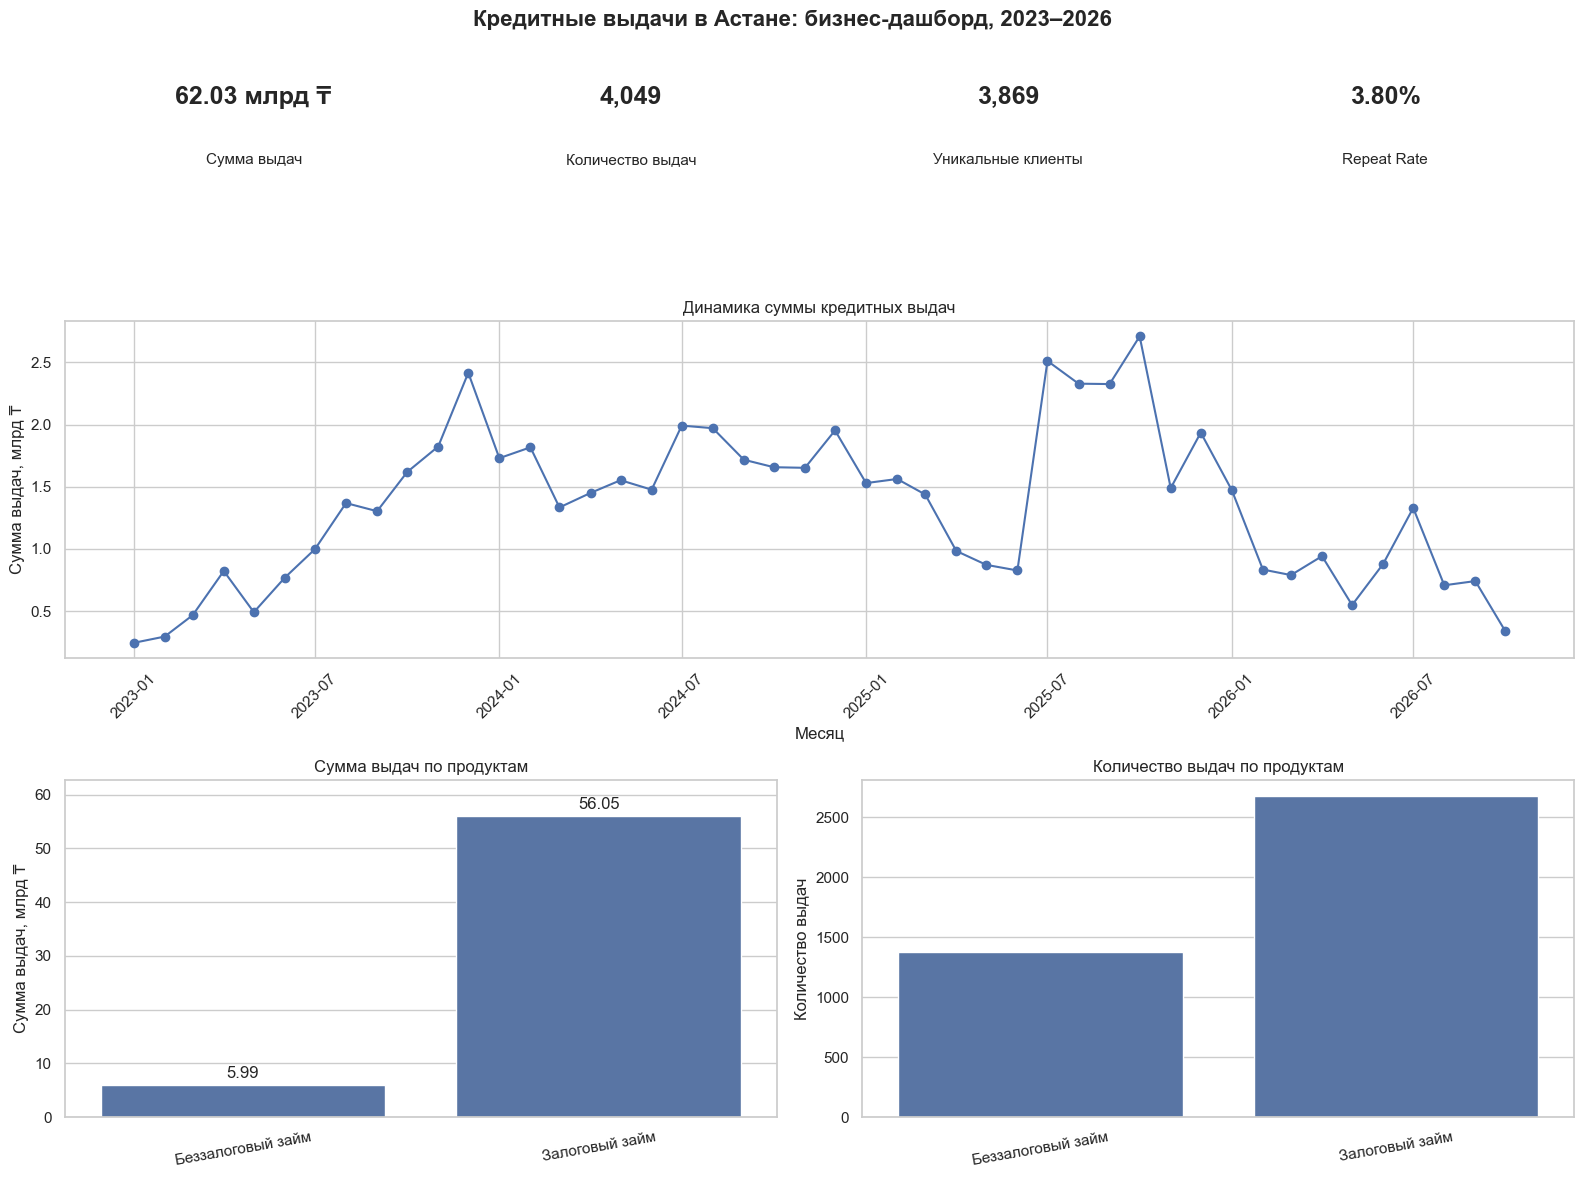

In [7]:

# 8.2. Итоговый бизнес-дашборд

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

# Подготовка агрегатов
dashboard_df = df.copy()
dashboard_df["Месяц_даты"] = (
    dashboard_df["Дата_выдачи"].dt.to_period("M").dt.to_timestamp()
)

monthly_dashboard = (
    dashboard_df.groupby("Месяц_даты")
    .agg(
        Сумма_выдач=("Сумма_выдачи_KZT", "sum"),
        Количество_выдач=("Счетчик_выдачи", "sum")
    )
    .reset_index()
)

product_dashboard = (
    dashboard_df.groupby("Продукт")
    .agg(
        Количество_выдач=("Счетчик_выдачи", "sum"),
        Сумма_выдач=("Сумма_выдачи_KZT", "sum")
    )
    .reset_index()
)

# KPI
total_amount = dashboard_df["Сумма_выдачи_KZT"].sum()
total_issuances = dashboard_df["Счетчик_выдачи"].sum()
total_customers = dashboard_df["Клиент_ID"].nunique()
repeat_customers = (
    dashboard_df.groupby("Клиент_ID")["Счетчик_выдачи"].sum() > 1
).sum()
repeat_rate = repeat_customers / total_customers * 100

fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2, height_ratios=[0.7, 1.5, 1.5])

# KPI-блок
ax_kpi = fig.add_subplot(gs[0, :])
ax_kpi.axis("off")

kpis = [
    ("Сумма выдач", f"{total_amount / 1e9:.2f} млрд ₸"),
    ("Количество выдач", f"{total_issuances:,.0f}"),
    ("Уникальные клиенты", f"{total_customers:,.0f}"),
    ("Repeat Rate", f"{repeat_rate:.2f}%")
]

for i, (label, value) in enumerate(kpis):
    x = 0.125 + i * 0.25
    ax_kpi.text(
        x, 0.65, value,
        ha="center", va="center",
        fontsize=18, fontweight="bold",
        transform=ax_kpi.transAxes
    )
    ax_kpi.text(
        x, 0.25, label,
        ha="center", va="center",
        fontsize=11,
        transform=ax_kpi.transAxes
    )

# Динамика суммы выдач
ax1 = fig.add_subplot(gs[1, :])
ax1.plot(
    monthly_dashboard["Месяц_даты"],
    monthly_dashboard["Сумма_выдач"] / 1e9,
    marker="o"
)
ax1.set_title("Динамика суммы кредитных выдач")
ax1.set_xlabel("Месяц")
ax1.set_ylabel("Сумма выдач, млрд ₸")
ax1.tick_params(axis="x", rotation=45)


# Сумма по продуктам — в миллиардах тенге
ax2 = fig.add_subplot(gs[2, 0])

product_dashboard["Сумма_выдач_млрд"] = (
    product_dashboard["Сумма_выдач"] / 1e9
)

sns.barplot(
    data=product_dashboard,
    x="Продукт",
    y="Сумма_выдач_млрд",
    ax=ax2
)

ax2.set_title("Сумма выдач по продуктам")
ax2.set_xlabel("")
ax2.set_ylabel("Сумма выдач, млрд ₸")
ax2.tick_params(axis="x", rotation=10)

# Подписи значений над столбцами
for container in ax2.containers:
    ax2.bar_label(container, fmt="%.2f", padding=3)

ax2.set_ylim(
    0,
    product_dashboard["Сумма_выдач_млрд"].max() * 1.12
)


# Количество по продуктам
ax3 = fig.add_subplot(gs[2, 1])
sns.barplot(
    data=product_dashboard,
    x="Продукт",
    y="Количество_выдач",
    ax=ax3
)
ax3.set_title("Количество выдач по продуктам")
ax3.set_xlabel("")
ax3.set_ylabel("Количество выдач")
ax3.tick_params(axis="x", rotation=10)

fig.suptitle(
    "Кредитные выдачи в Астане: бизнес-дашборд, 2023–2026",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
fig.savefig(
    r"C:\Users\User\project1_fintech\dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()




### Выводы по бизнес-дашборду

Дашборд объединяет ключевые показатели кредитных выдач, временную динамику и сравнение кредитных продуктов.

Основные наблюдения:
- За исследуемый период зарегистрировано 4 049 выдач на общую сумму 62,03 млрд ₸.
- Залоговые займы обеспечивают основную часть объёма кредитования.
- Повторные выдачи зафиксированы у 3,80% уникальных клиентов.
- Динамика суммы выдач менялась по годам; в январе–сентябре 2026 года наблюдалось снижение относительно аналогичного периода 2025 года.
- Последний месяц на графике — октябрь 2026 года — представлен неполными данными.

Дашборд предназначен для мониторинга основных показателей и выявления направлений для дальнейшего анализа. Он не устанавливает причины изменения объёмов кредитования.




## 9. Выводы и рекомендации (Business Insights & Recommendations)

### Основные результаты исследования

В рамках проекта проведён анализ кредитных выдач одной команды в Астане за 2023–2026 годы на основе 4 049 записей.

Основные результаты:

1. **Объём кредитования.** Общая сумма выдач составила 62,03 млрд ₸. В датасете представлено 3 869 уникальных клиентов.

2. **Структура продуктов.** Залоговые займы формируют 90,35% общей суммы выдач и 66,09% количества выдач. Средний размер залогового займа существенно превышает средний размер беззалогового займа.

3. **Повторная активность клиентов.** У 147 клиентов зарегистрированы повторные выдачи. Доля таких клиентов составляет 3,80% от общей клиентской базы за исследуемый период.

4. **Динамика кредитования.** При сравнении января–сентября сумма выдач выросла на 122,48% в 2024 году, снизилась на 4,40% в 2025 году и на 42,66% в 2026 году относительно предыдущего года.

5. **Проверка сезонности.** Статистически значимые различия между календарными месяцами не выявлены при уровне значимости 0,05. Наличие устойчивой сезонности не подтверждено.

6. **Прогнозирование.** Модель линейной регрессии показала низкое качество прогноза: R² = -16,088, MAE ≈ 1,08 млрд ₸. В текущем виде модель не подходит для бизнес-прогнозирования.

### Результаты проверки бизнес-гипотез

- **H1 — динамика выдач различается между годами:** гипотеза получила статистическую поддержку. Тест Краскела — Уоллиса выявил различия между годовыми группами месячных сумм выдач.
- **H2 — суммы выдач различаются по продуктам:** гипотеза получила статистическую поддержку. Тест Манна — Уитни выявил различия между распределениями сумм залоговых и беззалоговых займов.
- **H3 — существует сезонность кредитных выдач:** статистически значимые различия между календарными месяцами не подтверждены.

Статистические различия не устанавливают причины наблюдаемых изменений.

### Бизнес-рекомендации

1. **Изучить причины снижения выдач в 2026 году.** Проверить изменения клиентского потока, количества заявок, одобрений, конверсии и доступности кредитных продуктов. Эти данные отсутствуют в текущем датасете и требуют отдельного анализа.

2. **Анализировать продукты раздельно.** Отслеживать количество выдач, средний размер кредита и общую сумму по залоговым и беззалоговым займам. Это позволит точнее оценивать вклад каждого продукта в общий объём кредитования.

3. **Изучить повторную активность клиентов.** Проверить, какие клиенты возвращаются за кредитами, через какой срок происходят повторные выдачи и какие продукты выбирают повторные клиенты.

4. **Улучшить прогнозирование.** Сравнить линейную регрессию с базовым прогнозом и моделями временных рядов. Использовать хронологическую валидацию и учитывать изменения объёмов кредитования.

5. **Развивать управленческий мониторинг.** Регулярно отслеживать сумму и количество выдач, продуктовую структуру и динамику показателей на сопоставимых периодах.

### Ограничения исследования

- Данные за октябрь 2026 года неполные, поэтому годовые сравнения выполнены на сопоставимом периоде январь–сентябрь.
- Датасет содержит сведения о состоявшихся выдачах, но не содержит данных о заявках, отказах, расходах на привлечение клиентов и прибыли.
- Доля повторных выдач не является полноценным показателем удержания клиентов (Retention Rate).
- Статистические результаты требуют осторожной интерпретации с учётом временной структуры данных.
- Низкое качество линейной регрессии не позволяет использовать её прогнозы для непосредственного бизнес-планирования.

### Итоговый вывод

Исследование выявило значительную роль залоговых займов в денежном объёме кредитования, различия в динамике выдач между годами и низкую долю клиентов с повторными выдачами в пределах наблюдаемого периода.

Полученные результаты формируют основу для дальнейшего анализа причин снижения выдач, поведения клиентов и эффективности кредитных продуктов. Для принятия управленческих решений рекомендуется дополнить датасет показателями воронки продаж, одобрения заявок и финансовой эффективности.
